# Protein Function Prediction: Data Preparation
## Meeting 2 | Team 2

**Research question:** Can we predict the functions of a protein from its amino-acid sequence?

The future model will receive a protein sequence and output probabilities for
**Gene Ontology (GO) terms**. This is a **multi-label classification** task: a single
protein may participate in several processes, have multiple molecular functions,
and occur in different cellular components.

**This meeting:** build a reproducible, well-annotated dataset and a defensible
train/validation/test split. We do not train or evaluate a predictive model yet.

**Team 2 organisms:** *Candida albicans*, *Candida parapsilosis*, and
*Saccharomyces cerevisiae* (baker's yeast).

The code cells execute the complete preparation workflow. The implementation is
shared with the project modules in `src/`; no earlier notebook needs to be run.
Run all cells from top to bottom using **Python (BioInformatics)**.


In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import hashlib
import importlib.metadata
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Markdown

# Locate the project from either its root or the notebooks directory.
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src/data_loading.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the BioInformatics project.")
sys.path.insert(0, str(ROOT))

from src.data_loading import (
    ORGANISMS, EVIDENCE_CODES, SEED, download_all, load_all,
    validate_and_summarize, sha256,
)
from src.meeting2_preparation import (
    download_go_evidence, prepare_master, build_groups,
    assign_splits, validate_outputs, parse_go_ids,
)

for directory in ["data/raw/gaf", "data/raw/uniprot", "data/interim",
                  "data/processed", "reports"]:
    (ROOT / directory).mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 115, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold",
})
COLORS = {"train": "#2674A6", "eval": "#D99429", "test": "#26816B"}
SPECIES = [item["species"] for item in ORGANISMS]
SHORT_NAMES = {"Candida albicans": "C. albicans",
               "Candida parapsilosis": "C. parapsilosis",
               "Saccharomyces cerevisiae": "S. cerevisiae"}

def run_stage(title, function, *args, **kwargs):
    """Present consistent English progress messages for shared project code."""
    print(f"{title} ...", flush=True)
    start = time.perf_counter()
    # Shared modules have older diagnostic text; keep this presentation in English.
    with redirect_stdout(StringIO()):
        result = function(*args, **kwargs)
    print(f"Completed in {time.perf_counter() - start:.1f} seconds.")
    return result

def save_figure(fig, name):
    directory = ROOT / "reports/meeting_02_figures"
    directory.mkdir(exist_ok=True)
    fig.savefig(directory / name, dpi=170, bbox_inches="tight")
    plt.show()

print("Project:", ROOT)
print("Python:", sys.version.split()[0])
print("Random seed:", SEED)


Project: /home/sehruz/projekty/semestr9/BioInformatics/Protein-function-prediction
Python: 3.14.4
Random seed: 42


## 1. What are we building, and why?

An input example is an amino-acid sequence such as `M...K`. Its target is a **set**
of GO terms, rather than a single class. GO covers molecular function (MF),
biological process (BP), and cellular component (CC).

We need two complementary sources:

- **UniProt reviewed / Swiss-Prot:** protein identifiers, sequences, taxonomy,
  and the reference set of GO terms.
- **GO UniProt-centric GAF:** structured annotation records with evidence codes,
  relations (including `NOT`), and provenance.

Reviewed status applies to the **protein entry**; evidence codes describe
**individual annotations**. These are separate filters.

The workflow below follows the assignment and adds explicit checks for annotation
conflicts, duplicate sequences, and detected similarity across dataset splits.


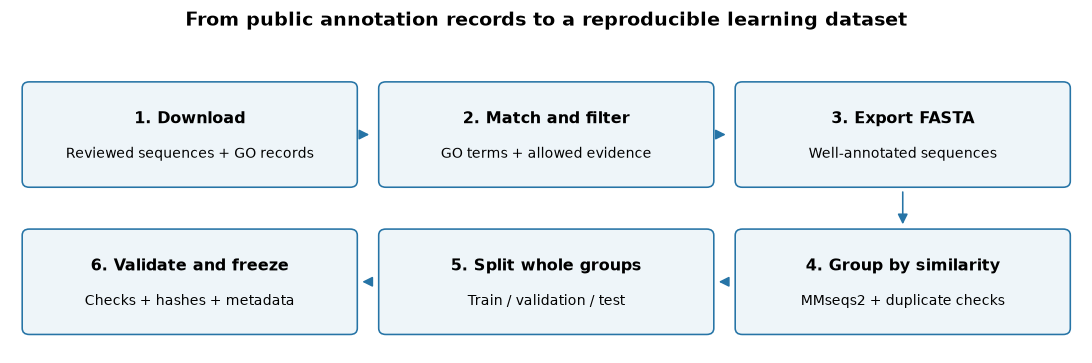

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis("off")
steps = [
    (0.2, 2.2, "1. Download", "Reviewed sequences + GO records"),
    (4.2, 2.2, "2. Match and filter", "GO terms + allowed evidence"),
    (8.2, 2.2, "3. Export FASTA", "Well-annotated sequences"),
    (8.2, 0.3, "4. Group by similarity", "MMseqs2 + duplicate checks"),
    (4.2, 0.3, "5. Split whole groups", "Train / validation / test"),
    (0.2, 0.3, "6. Validate and freeze", "Checks + hashes + metadata"),
]
for x, y, title, detail in steps:
    ax.add_patch(FancyBboxPatch((x, y), 3.6, 1.2,
        boxstyle="round,pad=0.08", facecolor="#EEF5F9", edgecolor="#2674A6"))
    ax.text(x + 1.8, y + 0.8, title, ha="center", va="center", weight="bold")
    ax.text(x + 1.8, y + 0.35, detail, ha="center", va="center", fontsize=8.5)
for start, end in [((3.9, 2.8), (4.05, 2.8)), ((7.9, 2.8), (8.05, 2.8)),
                   ((10, 2.1), (10, 1.6)), ((8.05, 0.9), (7.9, 0.9)),
                   ((4.05, 0.9), (3.9, 0.9))]:
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>",
                                mutation_scale=13, color="#2674A6"))
ax.set_title("From public annotation records to a reproducible learning dataset", pad=10)
save_figure(fig, "01_workflow.png")


## 2. Download and inspect the source data

We query each organism and its descendant taxa (including strains), keeping
**reviewed entries only** in UniProt. GAF files are downloaded separately and
matched to reviewed proteins later.

The additional UniProt JSON export provides `GoEvidenceType` for individual GO
annotations. It must agree with the TSV on release, protein identifiers, and GO sets.

Downloads are paginated or streamed, saved locally, and accompanied by metadata:
access time, query/URLs, available source versions, file size, and SHA256 hash.
Existing files are reused only after checksum verification.

Sources: [GO annotation downloads](https://geneontology.org/docs/download-go-annotations/downloads/),
[UniProt API](https://www.uniprot.org/api-documentation/uniprotkb).


In [3]:
organism_table = pd.DataFrame(ORGANISMS).rename(columns={
    "species": "Organism", "taxon_id": "Query taxonomy ID", "go_code": "GO file prefix",
})
display(organism_table)
downloads = run_stage("Download or verify GAF and reviewed UniProt TSV files", download_all, ROOT)
run_stage("Download or verify UniProt GO evidence", download_go_evidence, ROOT)
proteins, annotations = load_all(ROOT)
source_summary = validate_and_summarize(proteins, annotations)
display(source_summary[["species", "reviewed_proteins", "with_GO_in_UniProt", "GAF_rows"]]
        .rename(columns={"species": "Organism", "reviewed_proteins": "Reviewed proteins",
                         "with_GO_in_UniProt": "Proteins with UniProt GO",
                         "GAF_rows": "Raw GAF annotation rows"}))
memory_mib = (proteins.memory_usage(deep=True).sum()
              + annotations.memory_usage(deep=True).sum()) / 1024**2
print(f"In-memory source tables: {memory_mib:.1f} MiB (excluding kernel overhead and copies).")


,Organism,Query taxonomy ID,GO file prefix
0,Candida albicans,5476,CANAL
1,Candida parapsilosis,5480,CANPC
2,Saccharomyces cerevisiae,4932,YEAST


Download or verify GAF and reviewed UniProt TSV files ...


Completed in 0.0 seconds.
Download or verify UniProt GO evidence ...


Completed in 0.0 seconds.


,Organism,Reviewed proteins,Proteins with UniProt GO,Raw GAF annotation rows
0,Candida albicans,1466,1458,67191
1,Candida parapsilosis,23,23,54142
2,Saccharomyces cerevisiae,7919,7204,137564


In-memory source tables: 279.4 MiB (excluding kernel overhead and copies).


**How to read the counts:** a GAF row is an annotation record, not a unique
protein. Several rows may describe the same protein-GO pair with different evidence.
GAF files can include unreviewed proteins, so their row counts cannot be compared
directly with the number of reviewed UniProt entries.


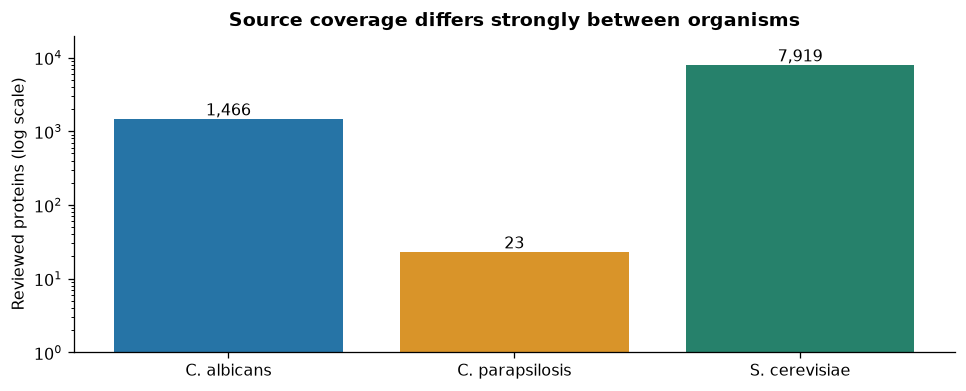

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.5))
counts = proteins.groupby("species").size().reindex(SPECIES)
bars = ax.bar([SHORT_NAMES[s] for s in counts.index], counts.values,
              color=["#2674A6", "#D99429", "#26816B"])
ax.set_yscale("log")
ax.set_ylim(1, counts.max() * 2.5)
for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, value * 1.12, f"{value:,}", ha="center")
ax.set_ylabel("Reviewed proteins (log scale)")
ax.set_title("Source coverage differs strongly between organisms")
fig.tight_layout()
save_figure(fig, "02_reviewed_coverage.png")


## 3. Reconcile annotation sources and select trustworthy labels

### Why compare GO annotations?
UniProt and GAF may disagree because of release dates, organism/strain scope,
identifier mapping, or annotation updates. We preserve their full direct GO sets
and record differences in both directions, rather than silently replacing one source.

### Our label policy
The reference set of GO terms comes from **UniProt**, as required by the assignment.
For each protein-GO pair we require:

1. The GO term exists in that protein's UniProt GO set.
2. At least one allowed evidence code is available in UniProt or a matching GAF record.
3. There is no exact conflicting `NOT` annotation in the matching GAF.

GAF matching requires the same protein identifier and taxonomy, and no conflicting
isoform-specific identifier. We retain a protein only if at least one label survives.

**Allowed evidence codes:** `EXP, IDA, IPI, IMP, IGI, IEP, HTP, HDA, HMP, HGI, HEP, TAS, IC`.
Evidence filtering applies to **each annotation**, not to all functions of a protein
just because one of its annotations has good evidence.


In [5]:
# An illustrative rule example, not actual biological records.
policy_example = pd.DataFrame([
    ["Term A", True, "IDA", False, "Keep"],
    ["Term B", True, "IEA", False, "Exclude: evidence not allowed"],
    ["Term C", True, "IMP", True, "Exclude: exact NOT conflict"],
    ["Term D", False, "IDA", False, "Exclude: outside UniProt GO set"],
], columns=["Illustrative term", "In UniProt GO", "Evidence", "GAF NOT conflict", "Decision"])
display(policy_example)

master, eligible, filtering = run_stage("Match annotations, audit evidence, and export FASTA",
                                       prepare_master, ROOT)
display(filtering.rename(columns={
    "reviewed": "Reviewed", "with_matching_positive_GAF": "With matching positive GAF",
    "identical_GO_sets": "Identical GO sets", "retained": "Retained", "excluded": "Excluded",
}).rename_axis("Organism"))
policy = json.loads((ROOT / "reports/annotation_policy.json").read_text())
print(f"Retained proteins: {len(eligible):,}")
print(f"Unique direct GO terms: {policy['unique_GO_terms']:,}")
print(f"Unique protein-GO label pairs: {policy['selected_label_pairs']:,}")


,Illustrative term,In UniProt GO,Evidence,GAF NOT conflict,Decision
0,Term A,True,IDA,False,Keep
1,Term B,True,IEA,False,Exclude: evidence not allowed
2,Term C,True,IMP,True,Exclude: exact NOT conflict
3,Term D,False,IDA,False,Exclude: outside UniProt GO set


Match annotations, audit evidence, and export FASTA ...


Completed in 4.3 seconds.


,Reviewed,With matching positive GAF,Identical GO sets,Retained,Excluded
Organism,,,,,
Candida albicans,1466,1192,83,704,762
Candida parapsilosis,23,7,0,9,14
Saccharomyces cerevisiae,7919,6057,845,5543,2376


Retained proteins: 6,256
Unique direct GO terms: 5,265
Unique protein-GO label pairs: 39,211


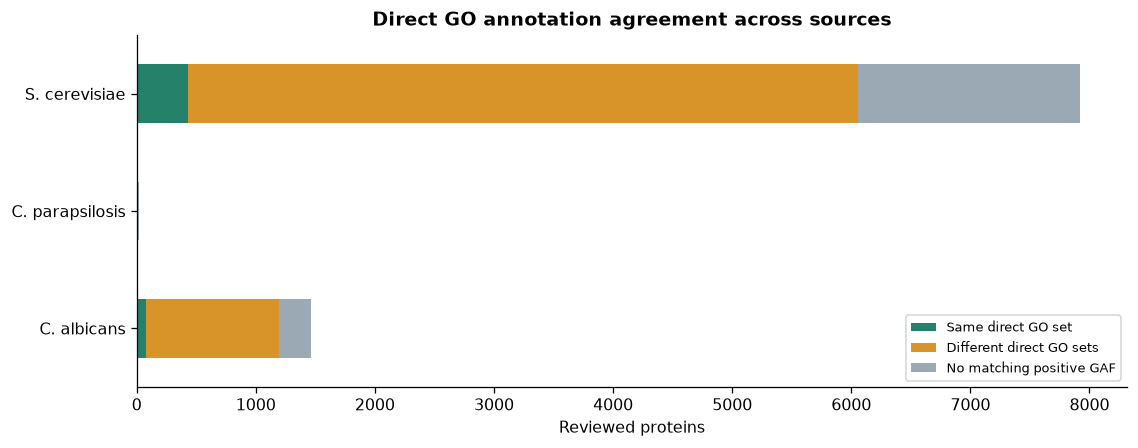

Comparison,Same direct GO set,Different direct GO sets,No matching positive GAF
species,,,
C. albicans,79,1113,274
C. parapsilosis,0,7,16
S. cerevisiae,433,5624,1862


In [6]:
# Distinguish missing GAF coverage from disagreements between two observed GO sets.
comparison = master.copy()
comparison["Comparison"] = np.select([
    ~comparison.has_matching_gaf,
    comparison.same_go_sets,
], ["No matching positive GAF", "Same direct GO set"], default="Different direct GO sets")
comparison_counts = pd.crosstab(comparison.species, comparison["Comparison"]).reindex(SPECIES)
comparison_counts = comparison_counts.reindex(columns=[
    "Same direct GO set", "Different direct GO sets", "No matching positive GAF"], fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
comparison_counts.rename(index=SHORT_NAMES).plot.barh(
    stacked=True, ax=ax, color=["#26816B", "#D99429", "#9AA9B4"])
ax.set_xlabel("Reviewed proteins")
ax.set_ylabel("")
ax.set_title("Direct GO annotation agreement across sources")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
save_figure(fig, "03_source_agreement.png")
display(comparison_counts.rename(index=SHORT_NAMES))


The comparison above uses **direct positive annotations**, without propagation
to GO ancestors. "No matching positive GAF" is a coverage category; it does not
mean that the protein has no function. A protein can still be retained when UniProt
provides an allowed evidence code.

The following plot shows the effect of filtering. A logarithmic axis keeps the
small *C. parapsilosis* sample visible. Full rejection decisions and source differences
are preserved in audit tables.


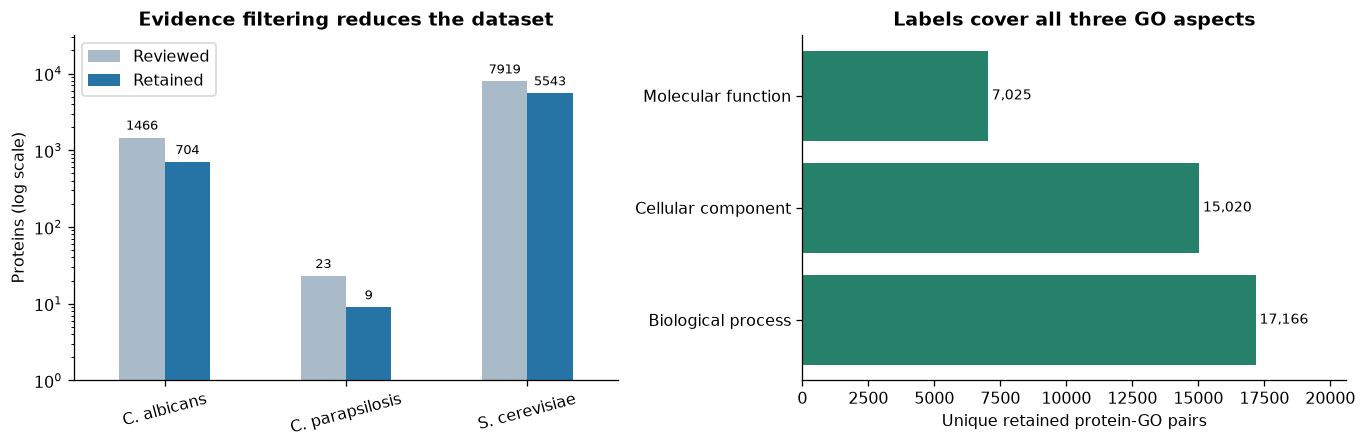

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_filter = filtering.reindex(SPECIES)[["reviewed", "retained"]].rename(
    index=SHORT_NAMES, columns={"reviewed": "Reviewed", "retained": "Retained"})
plot_filter.plot.bar(ax=axes[0], color=["#A9BAC8", "#2674A6"], rot=15)
axes[0].set_yscale("log")
axes[0].set_ylim(1, plot_filter.to_numpy().max() * 4)
axes[0].set_ylabel("Proteins (log scale)")
axes[0].set_xlabel("")
axes[0].set_title("Evidence filtering reduces the dataset")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fontsize=8)

selected_evidence = pd.read_csv(ROOT / "data/processed/label_evidence.tsv", sep="\t")
label_aspects = selected_evidence[["protein_id", "go_id", "aspect"]].drop_duplicates()
if label_aspects.groupby(["protein_id", "go_id"]).aspect.nunique().max() != 1:
    raise ValueError("Conflicting GO aspects require investigation.")
aspect_names = {"P": "Biological process", "F": "Molecular function", "C": "Cellular component"}
aspect_counts = label_aspects.aspect.map(aspect_names).value_counts()
axes[1].barh(aspect_counts.index, aspect_counts.values, color="#26816B")
axes[1].set_xlabel("Unique retained protein-GO pairs")
axes[1].set_title("Labels cover all three GO aspects")
for i, value in enumerate(aspect_counts):
    axes[1].text(value, i, f" {value:,}", va="center", fontsize=9)
axes[1].set_xlim(0, aspect_counts.max() * 1.2)
fig.tight_layout()
save_figure(fig, "04_filtering_and_go_aspects.png")


## 4. Build the master table and inspect sequences

The joined master table links the sequence and taxonomy to both source GO sets,
their differences, and the final filtered labels:

- `master_all_reviewed.tsv`: every reviewed protein, including excluded entries.
- `master_filtered.tsv`: only proteins with at least one eligible GO label.
- `proteins.fasta`: the corresponding sequences, ready for sequence clustering.

`go_ids_uniprot` is the full reference set before evidence filtering.
**`go_ids` contains the final targets for future learning.**

FASTA headers contain protein identifiers; GO labels remain in TSV files.
Sequence hashes identify exact duplicate sequences even when accessions differ.


,Protein ID,Organism,Taxonomy ID,Length (aa),Label count,Selected GO terms
0,A0A023PXP4,Saccharomyces cerevisiae,559292,132,1,GO:0006974
1,A0A023PZB3,Saccharomyces cerevisiae,559292,126,1,GO:0005739
2,A0A1D8PC43,Candida albicans,237561,362,3,GO:0004163;GO:0016126;GO:0019287
3,A0A1D8PCB9,Candida albicans,237561,217,2,GO:0000247;GO:0071466
4,A0A1D8PCD3,Candida albicans,237561,156,1,GO:0005886


Unique amino-acid sequences: 6,220
Additional accessions sharing an exact sequence: 36


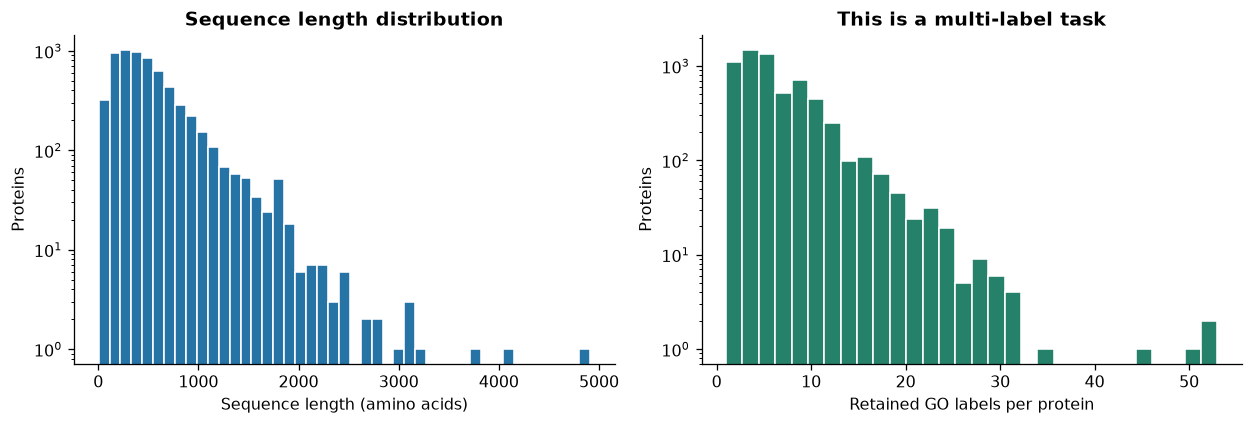

In [8]:
display(eligible[["protein_id", "species", "taxon_id", "length", "n_labels", "go_ids"]]
        .head(5).rename(columns={
            "protein_id": "Protein ID", "species": "Organism", "taxon_id": "Taxonomy ID",
            "length": "Length (aa)", "n_labels": "Label count", "go_ids": "Selected GO terms"}))

print(f"Unique amino-acid sequences: {eligible.sequence_sha256.nunique():,}")
print(f"Additional accessions sharing an exact sequence: "
      f"{len(eligible) - eligible.sequence_sha256.nunique():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(eligible.length, bins=45, color="#2674A6", edgecolor="white")
axes[0].set_xlabel("Sequence length (amino acids)")
axes[0].set_ylabel("Proteins")
axes[0].set_yscale("log")
axes[0].set_title("Sequence length distribution")
axes[1].hist(eligible.n_labels, bins=30, color="#26816B", edgecolor="white")
axes[1].set_xlabel("Retained GO labels per protein")
axes[1].set_ylabel("Proteins")
axes[1].set_yscale("log")
axes[1].set_title("This is a multi-label task")
fig.tight_layout()
save_figure(fig, "05_sequence_and_label_distributions.png")


## 5. Group similar proteins before splitting

### Why not assign proteins independently?
Closely related or identical sequences in both training and test data can make a
model appear more general than it is. We therefore assign **whole similarity groups**
to a single split.

The required clustering command is:

```bash
mmseqs easy-cluster proteins.fasta clusters temporary_directory \
  --min-seq-id 0.5 -c 0.8 --cov-mode 0
```

We also use `--alignment-mode 3` for explicit sequence identity,
`--cluster-reassign 1`, two CPU threads, and `--split-memory-limit 2G`.
The memory option limits large MMseqs2 structures; it is not a hard limit on the
entire Python process or WSL virtual machine.

To strengthen the separation, we run an additional all-vs-all `easy-search` with
the same identity/coverage thresholds and sensitivity `-s 7.5`.
Whole MMseqs2 clusters are merged when connected by an exact duplicate sequence
or a qualifying detected search hit. The resulting `cluster_id` is the split unit.

**Scope of the claim:** MMseqs2 search is heuristic. Zero detected cross-split hits
is not an exhaustive mathematical guarantee that no similar pair exists.


Cluster sequences and audit detected similarity ...


Completed in 0.6 seconds.


,Grouping statistic,Count
0,Initial MMseqs2 clusters,5504
1,Final groups used for splitting,5481
2,Qualifying non-self directed search hits,3983


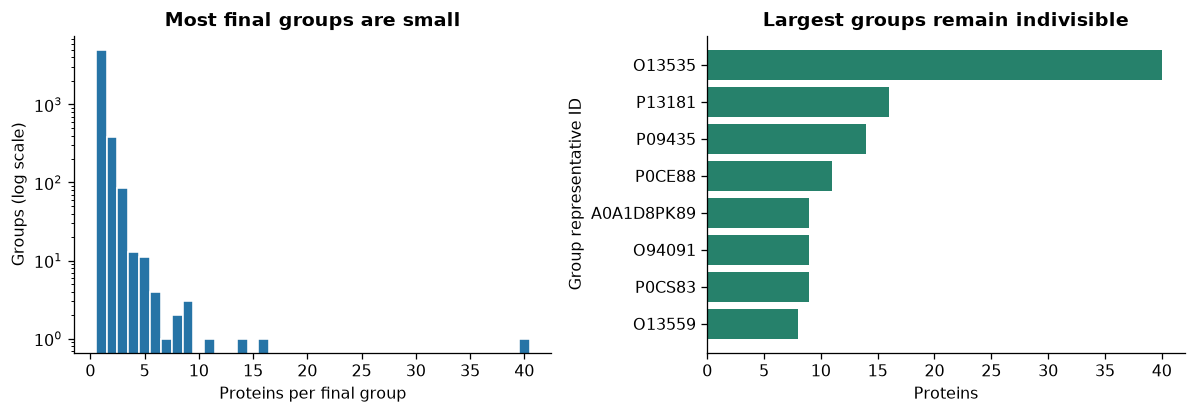

In [9]:
binary = ROOT / "tools/mmseqs/bin/mmseqs"
if not binary.is_file():
    raise FileNotFoundError("Run: python scripts/setup_project.py before clustering.")
grouped = run_stage("Cluster sequences and audit detected similarity", build_groups, ROOT, eligible)
cluster_report = json.loads((ROOT / "reports/clustering_summary.json").read_text())
display(pd.DataFrame([
    ["Initial MMseqs2 clusters", cluster_report["mmseqs_clusters"]],
    ["Final groups used for splitting", cluster_report["final_groups"]],
    ["Qualifying non-self directed search hits", cluster_report["nonself_qualifying_directed_hits"]],
], columns=["Grouping statistic", "Count"]))

group_sizes = grouped.groupby("cluster_id").size()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
axes[0].hist(group_sizes, bins=np.arange(0.5, group_sizes.max() + 1.5),
             color="#2674A6", edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_xlabel("Proteins per final group")
axes[0].set_ylabel("Groups (log scale)")
axes[0].set_title("Most final groups are small")
largest = group_sizes.nlargest(8)
axes[1].barh(range(len(largest)), largest.values, color="#26816B")
axes[1].set_yticks(range(len(largest)), largest.index)
axes[1].invert_yaxis()
axes[1].set_xlabel("Proteins")
axes[1].set_ylabel("Group representative ID")
axes[1].set_title("Largest groups remain indivisible")
fig.tight_layout()
save_figure(fig, "06_similarity_groups.png")


## 6. Assign whole groups to train, validation, and test

**Target:** 80% / 10% / 10% of **proteins**, not of clusters. In file names,
`eval` means the validation set.

We use seed **42** and **128 greedy restarts** with different group orderings.
The assignment considers dataset size, species balance, and common-label balance;
the best restart is selected by size and species error. A group is never split to
force an exact percentage.

Train will be used for fitting the model, validation for model/threshold selection,
and test for final assessment. No model performance is used to design this split.

The model's label vocabulary is constructed from **training labels only**.
We preserve all reference labels in validation/test and explicitly report terms
not observed in training instead of silently deleting them.


In [10]:
dataset, split_stats = run_stage("Assign whole groups to dataset splits", assign_splits,
                                ROOT, grouped, seed=SEED, trials=128)
display(split_stats.rename(columns={
    "proteins": "Proteins", "clusters": "Groups", "label_pairs": "Protein-GO pairs",
    "fraction": "Fraction of proteins",
}).rename_axis("Split"))
species_split = pd.crosstab(dataset.species, dataset.split).reindex(
    index=SPECIES, columns=["train", "eval", "test"], fill_value=0)
display(species_split.rename(index=SHORT_NAMES).rename_axis("Organism"))


Assign whole groups to dataset splits ...


Completed in 199.0 seconds.


,Proteins,Groups,Protein-GO pairs,Fraction of proteins
Split,,,,
train,5005,4382,31647,0.800032
eval,625,550,3791,0.099904
test,626,549,3773,0.100064


split,train,eval,test
Organism,,,
C. albicans,564,70,70
C. parapsilosis,7,1,1
S. cerevisiae,4434,554,555


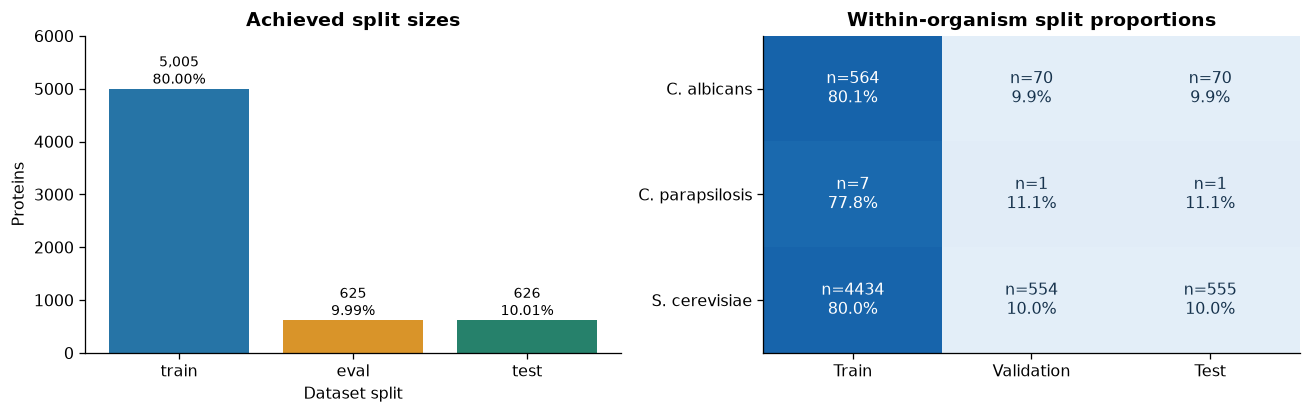

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
bars = axes[0].bar(split_stats.index, split_stats.proteins,
                   color=[COLORS[s] for s in split_stats.index])
for bar, value, fraction in zip(bars, split_stats.proteins, split_stats.fraction):
    axes[0].text(bar.get_x()+bar.get_width()/2, value,
                 f"{value:,}\n{fraction:.2%}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, split_stats.proteins.max() * 1.2)
axes[0].set_ylabel("Proteins")
axes[0].set_xlabel("Dataset split")
axes[0].set_title("Achieved split sizes")

proportions = species_split.div(species_split.sum(axis=1), axis=0)
axes[1].imshow(proportions.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(3), ["Train", "Validation", "Test"])
axes[1].set_yticks(range(3), [SHORT_NAMES[s] for s in SPECIES])
for i in range(3):
    for j in range(3):
        value = proportions.iloc[i, j]
        axes[1].text(j, i, f"n={species_split.iloc[i, j]}\n{value:.1%}",
                     ha="center", va="center", color="white" if value > 0.5 else "#17334D")
axes[1].set_title("Within-organism split proportions")
fig.tight_layout()
save_figure(fig, "07_dataset_splits.png")


## 7. Validate integrity and record reproducibility

The checks verify that:

- Every retained protein has one split and at least one selected label.
- Original clusters, final groups, and exact sequence duplicates do not cross splits.
- Every selected label belongs to UniProt's reference GO set and has allowed evidence.
- No exact GAF `NOT` conflicts were selected.
- No qualifying hit in the recorded similarity search crosses a split boundary.
- FASTA identifiers and full sequences agree with their corresponding TSV files.
- The training label vocabulary is derived only from training data.

SHA256 manifests detect subsequent file changes. A seed alone cannot freeze a
changing public database: exact reproduction also requires the original raw files,
their metadata, software versions, and the same MMseqs2 archive.


In [12]:
validation = run_stage("Validate exported data and write dataset checksums", validate_outputs,
                       ROOT, dataset)

def read_fasta(path):
    """Read FASTA records for an independent sequence-level export check."""
    records = {}
    identifier = None
    for line in path.read_text().splitlines():
        if line.startswith(">"):
            identifier = line[1:].strip()
            if identifier in records:
                raise ValueError("Duplicate FASTA identifier.")
            records[identifier] = ""
        elif line.strip():
            if identifier is None:
                raise ValueError("Sequence found before a FASTA header.")
            records[identifier] += line.strip()
    return records

for split in ["train", "eval", "test"]:
    subset = dataset[dataset.split.eq(split)]
    expected = dict(zip(subset.protein_id, subset.sequence))
    if read_fasta(ROOT / f"data/processed/splits/{split}.fasta") != expected:
        raise ValueError(f"FASTA/TSV sequence mismatch in {split}.")

vocabulary = pd.read_csv(ROOT / "data/processed/train_label_vocabulary.tsv", sep="\t")
training_terms = set().union(*(parse_go_ids(value)
    for value in dataset.loc[dataset.split.eq("train"), "go_ids"]))
if set(vocabulary.go_id) != training_terms:
    raise ValueError("The label vocabulary does not match training labels.")

checks = pd.DataFrame([
    ["Complete assignment and eligible labels", "PASS"],
    ["No group or exact duplicate crossing a split", "PASS"],
    ["Allowed annotation evidence and no selected NOT conflict", "PASS"],
    ["No detected qualifying cross-split similarity hit", "PASS"],
    ["FASTA identifiers and complete sequences match TSV", "PASS"],
    ["Label vocabulary uses training data only", "PASS"],
], columns=["Integrity check", "Result"])
display(checks)


Validate exported data and write dataset checksums ...


Completed in 0.3 seconds.


,Integrity check,Result
0,Complete assignment and eligible labels,PASS
1,No group or exact duplicate crossing a split,PASS
2,Allowed annotation evidence and no selected NO...,PASS
3,No detected qualifying cross-split similarity hit,PASS
4,FASTA identifiers and complete sequences match...,PASS
5,Label vocabulary uses training data only,PASS


In [13]:
source_versions = []
for org in ORGANISMS:
    prefix = org["go_code"]
    uniprot_meta = json.loads((ROOT / f"data/raw/uniprot/{prefix}-reviewed.tsv.metadata.json").read_text())
    gaf_meta = json.loads((ROOT / f"data/raw/gaf/{prefix}-uniprot.gaf.gz.metadata.json").read_text())
    gaf_date = next((line.split(":", 1)[1].strip()
        for line in gaf_meta["gaf_header"] if line.startswith("!date-generated:")), "Not provided")
    source_versions.append({"Organism": org["species"],
                            "UniProt release": uniprot_meta.get("uniprot_release", "Not provided"),
                            "GAF generation time": gaf_date,
                            "Downloaded at (UTC)": uniprot_meta["downloaded_at_utc"]})
display(pd.DataFrame(source_versions))

run_metadata = {
    "notebook": "meeting_02_data_preparation.ipynb",
    "language": "English", "seed": SEED, "split_trials": 128,
    "python": sys.version.split()[0],
    "packages": {name: importlib.metadata.version(name)
                 for name in ["pandas", "numpy", "matplotlib", "requests"]},
    "source_module_sha256": {str(p.relative_to(ROOT)): sha256(p)
        for p in [ROOT / "src/data_loading.py", ROOT / "src/meeting2_preparation.py"]},
    "validation": validation,
    "additional_sequence_and_vocabulary_checks": "passed",
}
(ROOT / "reports/meeting_02_notebook_run.json").write_text(json.dumps(run_metadata, indent=2))


,Organism,UniProt release,GAF generation time,Downloaded at (UTC)
0,Candida albicans,2026_03,2026-07-28 20:00,2026-10-27T13:45:11.511699+00:00
1,Candida parapsilosis,2026_03,2026-07-28 19:57,2026-10-27T13:45:13.325905+00:00
2,Saccharomyces cerevisiae,2026_03,2026-07-28 19:51,2026-10-27T13:45:38.502509+00:00


879

## 8. Results, limitations, and next steps

The tables below are generated from this run, so the presentation follows the actual
data rather than hard-coded headline numbers.


In [14]:
split_config = json.loads((ROOT / "reports/split_config.json").read_text())
display(Markdown(f"""
### Meeting 2 outcome

- **{len(proteins):,} reviewed proteins** were downloaded across the three organisms.
- **{len(dataset):,} proteins** remain after annotation-level evidence filtering.
- The dataset contains **{policy['selected_label_pairs']:,} protein-GO pairs**
  and **{policy['unique_GO_terms']:,} distinct direct GO terms**.
- **{cluster_report['final_groups']:,} whole similarity groups** were assigned to
  **{split_stats.loc['train', 'proteins']:,} train**,
  **{split_stats.loc['eval', 'proteins']:,} validation**, and
  **{split_stats.loc['test', 'proteins']:,} test** proteins.
- All implemented integrity checks passed.

### Limitations to disclose

- Only **{int(filtering.loc['Candida parapsilosis', 'retained'])} C. parapsilosis proteins**
  remain. One validation/test example cannot support a stable organism-specific estimate.
- **{split_config['unseen_GO_in_eval']} validation GO terms** and
  **{split_config['unseen_GO_in_test']} test GO terms** are absent from training.
  Evaluation must explicitly handle this incomplete label coverage.
- Missing annotations do not prove absence of a biological function.
- Similarity search is heuristic; zero detected cross-split hits is not an exhaustive proof.
- Current labels are direct GO annotations. Ancestor propagation, obsolete/alternate
  GO identifier handling, and the final evaluation policy are deferred to the evaluation stage.

### Next meeting

Build a working input/output skeleton using the frozen split files. Model training,
baseline comparisons, and predictive performance evaluation come later.
"""))



### Meeting 2 outcome

- **9,408 reviewed proteins** were downloaded across the three organisms.
- **6,256 proteins** remain after annotation-level evidence filtering.
- The dataset contains **39,211 protein-GO pairs**
  and **5,265 distinct direct GO terms**.
- **5,481 whole similarity groups** were assigned to
  **5,005 train**,
  **625 validation**, and
  **626 test** proteins.
- All implemented integrity checks passed.

### Limitations to disclose

- Only **9 C. parapsilosis proteins**
  remain. One validation/test example cannot support a stable organism-specific estimate.
- **220 validation GO terms** and
  **236 test GO terms** are absent from training.
  Evaluation must explicitly handle this incomplete label coverage.
- Missing annotations do not prove absence of a biological function.
- Similarity search is heuristic; zero detected cross-split hits is not an exhaustive proof.
- Current labels are direct GO annotations. Ancestor propagation, obsolete/alternate
  GO identifier handling, and the final evaluation policy are deferred to the evaluation stage.

### Next meeting

Build a working input/output skeleton using the frozen split files. Model training,
baseline comparisons, and predictive performance evaluation come later.


## 9. Where are the deliverables?

| Deliverable | Purpose |
|---|---|
| `data/raw/` and adjacent metadata | Original downloaded records and provenance |
| `data/processed/master_all_reviewed.tsv` | All reviewed proteins, source differences, and rejection decisions |
| `data/processed/master_filtered.tsv` | Well-annotated proteins before splitting |
| `data/processed/proteins.fasta` | Sequences used for clustering |
| `data/processed/clusters.tsv` | Original cluster and final group membership |
| `data/processed/master_split.tsv` | Final combined dataset with split assignments |
| `data/processed/splits/{train,eval,test}.{tsv,fasta}` | Model-ready split files |
| `data/processed/labels.tsv` | Protein-GO pairs with their assigned split |
| `data/processed/train_label_vocabulary.tsv` | Training-derived label indices |
| `reports/go_source_comparison.tsv` | Direct GO differences across sources |
| `reports/label_coverage.tsv` | Per-term train/validation/test coverage |
| `reports/validation.json` and `dataset_manifest.json` | Integrity results and data fingerprints |
| `reports/meeting_02_figures/` | English figures generated by this notebook |
| `reports/meeting_02_notebook_run.json` | Environment, source-code hashes, and additional checks |

### References

- [GO annotation downloads](https://geneontology.org/docs/download-go-annotations/downloads/)
- [GAF 2.2 format](https://geneontology.org/docs/go-annotation-file-gaf-format-2.2/)
- [GO evidence codes](https://geneontology.org/docs/guide-go-evidence-codes/)
- [UniProt API](https://www.uniprot.org/api-documentation/uniprotkb)
- [MMseqs2 user guide](https://github.com/soedinglab/MMseqs2/wiki)
